In [24]:
import re
import hashlib
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import imagehash
from tqdm import tqdm
from spellchecker import SpellChecker

from datasets import load_dataset
from sklearn.model_selection import train_test_split

import torch
from torchvision import transforms

## Caption analysis (before cleaning)

In [25]:
train = load_dataset("Multimodal-Fatima/CUB_train", split="train")
desc = train.select_columns(["description"])  # skip image decoding
raw = desc["description"]
print(len(raw))
print(repr(raw[0]))

5994
'this bird is brown with a lighter brown crest.\naquatic large bird with long hooked bill, white face, and brown body.\nbird has brown body feathers, brown breast feathers, and brown beak\nthis bird has a white superciliary and brown all around its body with a long bill\nthis is a brown bird with a white face and a long downward pointing beak.\nthis bird is brown with white and has a long, pointy beak.\nbrown duck playing on the lake making a poodle\nthis bird has wings that are brown and has a long bill\nthis bird has long brown bill, with a brown body.\nthis is a medium sized brown bird, with a long pointed bill.\n'


### 1. Split on newline: how many captions per image, empty lines, duplicates

In [26]:
split_caps = [d.split("\n") for d in raw]

n_caps = pd.Series([len(c) for c in split_caps])
n_empty = pd.Series([sum(1 for x in c if not x.strip()) for c in split_caps])
n_dupes = pd.Series([len([x.strip().lower() for x in c if x.strip()]) -
                     len({x.strip().lower() for x in c if x.strip()}) for c in split_caps])

print("captions per image:\n", n_caps.value_counts().sort_index())
print("images with empty lines:", (n_empty > 0).sum())
print("images with duplicate captions:", (n_dupes > 0).sum())

captions per image:
 11    5994
Name: count, dtype: int64
images with empty lines: 5994
images with duplicate captions: 583


In [27]:
print(repr(raw[0][-60:]))
print(repr(split_caps[0][-1]))

'his is a medium sized brown bird, with a long pointed bill.\n'
''


In [28]:
print(sum(any(not x.strip() for x in c[:-1]) for c in split_caps))

0


### 2. Caption length (words) and outliers

count    65934.000000
mean        13.854370
std          6.248034
min          0.000000
25%         12.000000
50%         13.000000
75%         17.000000
max         65.000000
dtype: float64


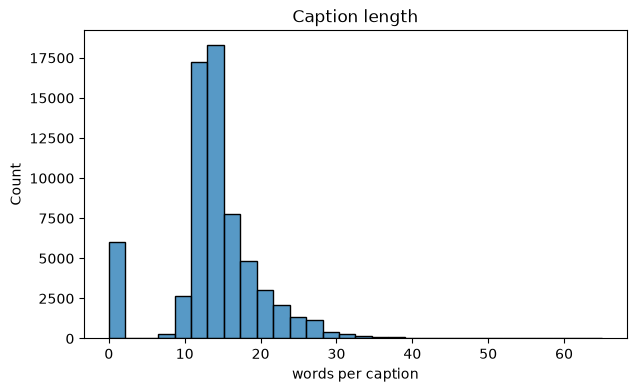

shortest:
['', '', '', '', '']
longest:
['this is a grayish bird with a stripe of black that extends from the top of its head through the eyes to the tip of the beak and down its neck along with a hint of white in the face, black, white, tan and pink wings, a black and yellow-tipped tail, and a round body with hints of reddish brown in the face and tail.', 'this small bird has a brown head with a raised tuft on the top of the head and a black eye mark that runs from the bill past the eye, then turns upward and goes to the top of the head, the bill is also black, the breast is light brown the belly and rump are faint green, the wings and tail are grey.', "this special bird has a color of reddish-brown that tapers to the tail with a uniform gray-brown very smooth looking plumage, he has a black cheek patch and eyebrow with a tiny black beak and feet, and you can't help but notice the tuft of red to brown hair that sicks straight out off the back of his crown because he is beautiful."]


In [29]:
caps = pd.Series([x for c in split_caps for x in c])
lens = caps.str.split().str.len()
print(lens.describe())

plt.figure(figsize=(7, 4))
sns.histplot(lens, bins=30)
plt.xlabel("words per caption"); plt.title("Caption length")
plt.show()

print("shortest:"); print(caps[lens.nsmallest(5).index].tolist())
print("longest:");  print(caps[lens.nlargest(3).index].tolist())

### 3. Case, whitespace and punctuation issues

In [30]:
checks = {
    "has uppercase": caps.str.contains(r"[A-Z]"),
    "double spaces": caps.str.contains(r"\s{2,}"),
    "leading/trailing space": caps != caps.str.strip(),
    "has digits": caps.str.contains(r"\d"),
    "ends with period": caps.str.strip().str.endswith("."),
}
for name, mask in checks.items():
    print(f"{name:25s} {mask.sum():6d}  ({mask.mean():.1%})")

punct = Counter(ch for x in caps for ch in x if not ch.isalnum() and not ch.isspace())
print("\npunctuation / symbols:", punct.most_common())

non_ascii = caps[caps.map(lambda s: not s.isascii())]
print("non-ascii captions:", len(non_ascii))

has uppercase                  0  (0.0%)
double spaces                  0  (0.0%)
leading/trailing space         0  (0.0%)
has digits                    65  (0.1%)
ends with period           46492  (70.5%)

punctuation / symbols: [(',', 52467), ('.', 47305), ('-', 1879), ("'", 1690), ('�', 848), ('/', 266), (';', 247), ('&', 196), ('"', 47), ('(', 25), (')', 25), (':', 13), ('!', 4), ('?', 4), ('`', 4), ('=', 1)]
non-ascii captions: 27


In [31]:
non_ascii.head()

2148    this��bird��has��a��black��body��and��white��b...
2237    this��bird��has��a��white��belly,��black��body...
2776    this��short��bird��has��a��spotted-white��eyer...
2875    this��bird��has��a��dark��brown��body,��black�...
5163    this��bird��has��a��red��breast��and��belly,��...
dtype: str

### 4. Vocabulary and typo candidates

In [32]:
clean_probe = caps.str.lower().str.replace(r"[^a-z\s]", " ", regex=True)
words = Counter(w for s in clean_probe for w in s.split())
print("vocab size:", len(words))
print("appear once:", sum(1 for c in words.values() if c == 1))
print("top 20:", words.most_common(20))

spell = SpellChecker()
unknown = spell.unknown(words.keys())
typos = sorted(((w, words[w]) for w in unknown), key=lambda x: -x[1])
print("unknown words:", len(typos))
print(typos[:40])

# suggested fixes for the most frequent unknown words
for w, c in typos[:15]:
    print(w, c, "->", spell.correction(w))

vocab size: 4045
appear once: 1849
top 20: [('a', 90704), ('and', 82990), ('bird', 59025), ('with', 40957), ('has', 40560), ('black', 39789), ('this', 37815), ('white', 33207), ('brown', 21772), ('is', 20969), ('beak', 18714), ('belly', 17426), ('small', 16860), ('wings', 15907), ('yellow', 15774), ('the', 15470), ('bill', 14701), ('long', 10939), ('grey', 10563), ('breast', 10204)]
unknown words: 792
[('wingbars', 1703), ('eyering', 1409), ('rectrices', 779), ('superciliary', 636), ('retrices', 332), ('wingbar', 301), ('eyerings', 206), ('undertail', 166), ('multi', 165), ('tarsuses', 79), ('supercillary', 68), ('bil', 65), ('cheekpatch', 42), ('tailfeathers', 42), ('rectrice', 41), ('superciliaries', 40), ('supercilliary', 34), ('retrice', 34), ('uppertail', 30), ('larsus', 29), ('orangish', 29), ('beek', 29), ('retricies', 27), ('rectices', 26), ('winglets', 25), ('whtie', 23), ('rectricles', 23), ('eyepatch', 20), ('recticles', 20), ('bely', 18), ('ish', 18), ('witha', 14), ('iwth'

## Cleaning the description column

Steps, in order: split on `\n`, strip, lowercase, punctuation (`-` to space, delete `'` and backtick, every other non-letter to space), collapse whitespace, fix known typos, drop empty captions, drop duplicates within an image (first copy kept, order preserved).

In [34]:
# Hand-built from the train typo list. Real bird terms (wingbar, eyering, rectrices, superciliary,
# undertail, uppertail, tarsuses, cheekpatch, tailfeathers, orangish, winglets, eyepatch, eyestripe...) are NOT touched.
TYPO_FIXES = {
    "retrices": "rectrices", "retricies": "rectrices", "retricles": "rectrices",
    "rectices": "rectrices", "rectricles": "rectrices", "recticles": "rectrices",
    "retrice": "rectrice",
    # second pass: spelling typos
    "smal": "small", "blck": "black", "balck": "black", "beack": "beak",
    "bakc": "back", "bak": "back", "brwon": "brown", "bornw": "brown",
    "corwn": "crown", "cown": "crown", "plummage": "plumage",
    "adn": "and", "amd": "and", "hwite": "white", "ehite": "white", "whie": "white", "shite": "white",
    "yelow": "yellow", "yello": "yellow", "yekkiw": "yellow", "gren": "green", "greay": "gray", "bluie": "blue",
    "brid": "bird", "bir": "bird", "bord": "bird", "burd": "bird",
    "bellt": "belly", "bellly": "belly", "gelly": "belly", "bellty": "belly", "bellyl": "belly", "eblly": "belly",
    "breats": "breast", "breat": "breast", "ehad": "head", "billl": "bill",
    "wiht": "with", "wih": "with", "wth": "with", "wtih": "with", "wiith": "with",
    "thraot": "throat", "thorat": "throat", "eyebro": "eyebrow", "eyelings": "eyerings", "eyeings": "eyerings",
    "tarus": "tarsus", "tarsas": "tarsus", "tarsis": "tarsus",
    "covarts": "coverts", "corvets": "coverts", "secondaires": "secondaries",
    "trinagular": "triangular", "camoflauged": "camouflaged", "camoflague": "camouflage",
    "irridescent": "iridescent", "flourescent": "fluorescent", "metalic": "metallic",
    "spikey": "spiky", "patterend": "patterned", "fluffly": "fluffy", "hgas": "has",
    # run-together words
    "withwhite": "with white", "withblack": "with black", "thisis": "this is",
    "andthe": "and the", "areblack": "are black", "greywith": "grey with",
    "supercillary": "superciliary", "supercilliary": "superciliary", "supercilary": "superciliary",
    "superciliaries": "superciliary",
    "bil": "bill", "beek": "beak", "whtie": "white", "bely": "belly",
    "iwth": "with", "witha": "with a", "redish": "reddish", "poitned": "pointed", "larsus": "tarsus",
}

def clean_caption(text):
    text = text.strip().lower()
    text = text.replace("-", " ")
    text = re.sub(r"['`]", "", text)          # bird's -> birds
    text = re.sub(r"[^a-z\s]", " ", text)     # , . / ; & " ( ) : ! ? = digits and the broken characters -> space
    words = text.split()                       # also collapses whitespace
    return " ".join(TYPO_FIXES.get(w, w) for w in words)

def clean_description(description):
    captions = [clean_caption(c) for c in description.split("\n")]
    captions = [c for c in captions if c]      # drop empty
    return list(dict.fromkeys(captions))       # drop duplicates, keep first copy and order

In [35]:
test = load_dataset("Multimodal-Fatima/CUB_test", split="test").select_columns(["description"])
raw_test = test["description"]

train_clean = [clean_description(d) for d in raw]
test_clean = [clean_description(d) for d in raw_test]

def report(name, raw_descs, cleaned):
    lines = [l for d in raw_descs for l in d.split("\n")]
    nonempty = [c for d in raw_descs for c in (clean_caption(l) for l in d.split("\n")) if c]
    kept = sum(len(c) for c in cleaned)
    counts = pd.Series([len(c) for c in cleaned])
    print(f"--- {name}: {len(cleaned)} images")
    print(f"lines after split:      {len(lines)}")
    print(f"empty lines dropped:    {len(lines) - len(nonempty)}")
    print(f"duplicates dropped:     {len(nonempty) - kept}")
    print(f"captions kept:          {kept}")
    print("captions per image:\n", counts.value_counts().sort_index().to_string())

report("train", raw, train_clean)
report("test", raw_test, test_clean)

--- train: 5994 images
lines after split:      65934
empty lines dropped:    5994
duplicates dropped:     651
captions kept:          59289
captions per image:
 7        1
8       57
9      534
10    5402
--- test: 5794 images
lines after split:      63734
empty lines dropped:    5794
duplicates dropped:     684
captions kept:          57256
captions per image:
 7        3
8       61
9      553
10    5177


In [36]:
# typos fixed in train (counts come from the probe vocabulary built earlier)
print("typo tokens fixed in train:", sum(words[w] for w in TYPO_FIXES if w in words))

# before / after
d = raw[0]
print("BEFORE:", d.split("\n")[:2])
print("AFTER: ", train_clean[0][:2])

# the corrupted-space captions: find an image whose description contained the broken character
bad = next(i for i, d in enumerate(raw) if "\ufffd" in d)
print("\nBEFORE:", [l for l in raw[bad].split("\n") if "\ufffd" in l][0])
print("AFTER: ", [c for c in train_clean[bad] if "thisbird" not in c][0])

typo tokens fixed in train: 1116
BEFORE: ['this bird is brown with a lighter brown crest.', 'aquatic large bird with long hooked bill, white face, and brown body.']
AFTER:  ['this bird is brown with a lighter brown crest', 'aquatic large bird with long hooked bill white face and brown body']

BEFORE: this��bird��has��a��black��body��and��white��belly,��a��slender��white��cheek��patch��originating��from��it's��eyes,��and��a��short,��rounded,��orange��bill.
AFTER:  this orange round billed bird is black on its wings and back and head it has a white cheek patch the breast and underside is white


In [37]:
flat = [c for caps_list in train_clean for c in caps_list]
words_after = Counter(w for s in flat for w in s.split())
print("vocab size:", len(words), "->", len(words_after))
print("unknown words:", len(spell.unknown(words_after.keys())))

vocab size: 4045 -> 3963
unknown words: 710


## Plots for the report (caption analysis and cleaning)

In [38]:
from pathlib import Path
FIG_DIR = Path("../outputs/figures"); FIG_DIR.mkdir(parents=True, exist_ok=True)

def save(name):
    plt.tight_layout(); plt.savefig(FIG_DIR / f"{name}.png", dpi=150); plt.show()

### Stage 1: split and drop empty/duplicate lines

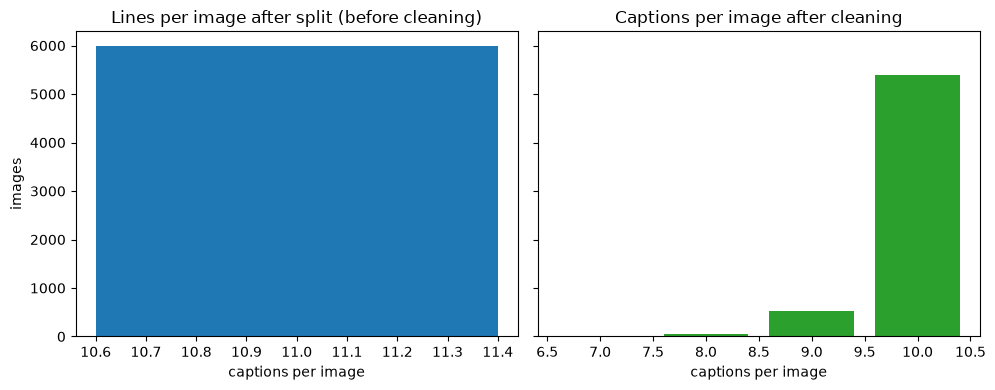

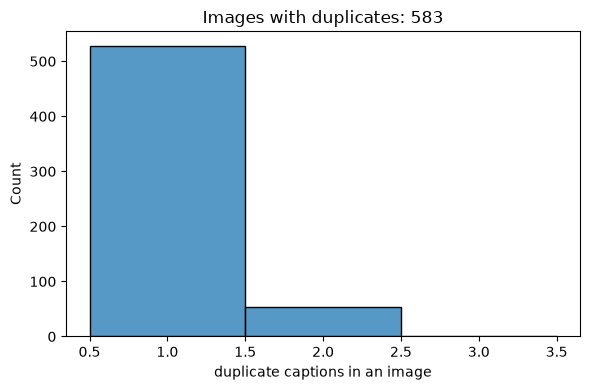

In [39]:
after_counts = pd.Series([len(c) for c in train_clean])
before_counts = n_caps.value_counts().sort_index()
after_vc = after_counts.value_counts().sort_index()

fig, ax = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
ax[0].bar(before_counts.index, before_counts.values); ax[0].set_title("Lines per image after split (before cleaning)")
ax[1].bar(after_vc.index, after_vc.values, color="tab:green"); ax[1].set_title("Captions per image after cleaning")
for a in ax: a.set_xlabel("captions per image")
ax[0].set_ylabel("images")
save("captions_per_image_before_after")

plt.figure(figsize=(6, 4))
sns.histplot(n_dupes[n_dupes > 0], discrete=True)
plt.xlabel("duplicate captions in an image"); plt.title(f"Images with duplicates: {(n_dupes > 0).sum()}")
save("duplicates_per_image")

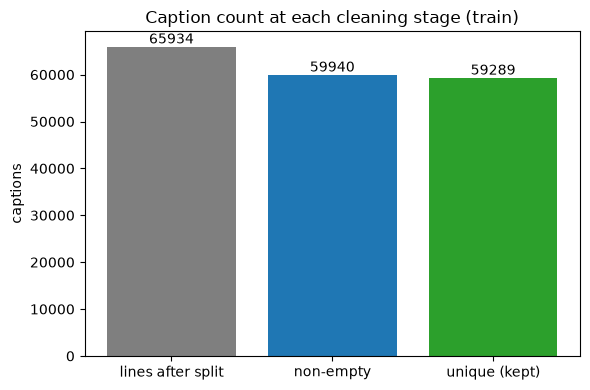

In [40]:
lines_total = sum(len(c) for c in split_caps)
nonempty_total = sum(1 for d in raw for l in d.split("\n") if clean_caption(l))
kept_total = sum(len(c) for c in train_clean)

stages = ["lines after split", "non-empty", "unique (kept)"]
vals = [lines_total, nonempty_total, kept_total]
plt.figure(figsize=(6, 4))
bars = plt.bar(stages, vals, color=["tab:gray", "tab:blue", "tab:green"])
plt.bar_label(bars); plt.ylabel("captions"); plt.title("Caption count at each cleaning stage (train)")
save("cleaning_funnel")

### Stage 2: case, whitespace, punctuation

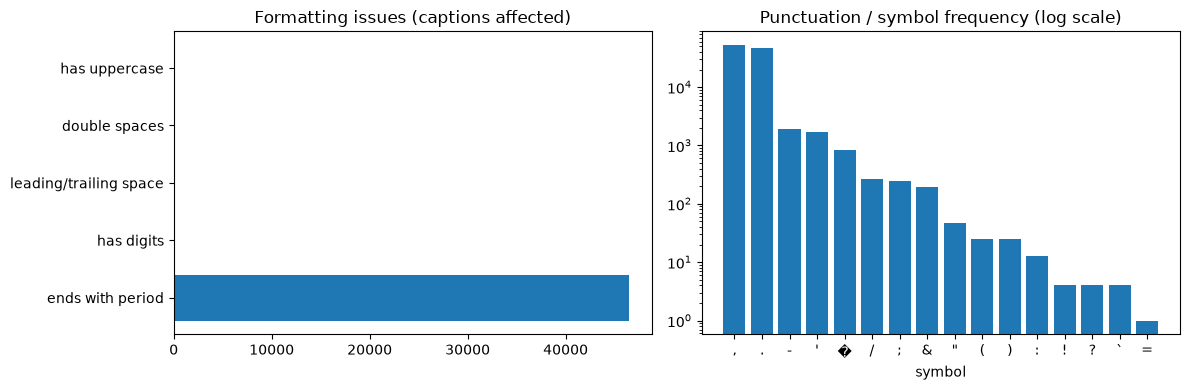

In [41]:
names = list(checks.keys())
counts = [int(checks[n].sum()) for n in names]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].barh(names, counts); ax[0].set_title("Formatting issues (captions affected)"); ax[0].invert_yaxis()

sym, cnt = zip(*punct.most_common())
ax[1].bar([repr(s)[1:-1] for s in sym], cnt); ax[1].set_yscale("log")
ax[1].set_title("Punctuation / symbol frequency (log scale)"); ax[1].set_xlabel("symbol")
save("formatting_and_punctuation")

### Stage 3: caption length before vs after cleaning

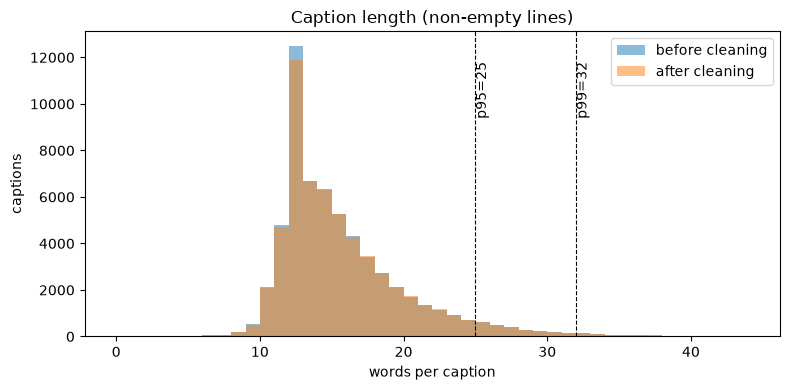

count    59289.000000
mean        15.317158
std          4.704950
min          1.000000
25%         12.000000
50%         14.000000
75%         17.000000
max         66.000000
dtype: float64


In [42]:
before_len = pd.Series([len(l.split()) for d in raw for l in d.split("\n") if l.strip()])
after_len = pd.Series([len(c.split()) for caps_list in train_clean for c in caps_list])

plt.figure(figsize=(8, 4))
bins = range(0, 45)
plt.hist(before_len, bins=bins, alpha=0.5, label="before cleaning")
plt.hist(after_len, bins=bins, alpha=0.5, label="after cleaning")
for q in (0.95, 0.99):
    plt.axvline(after_len.quantile(q), ls="--", c="k", lw=0.8)
    plt.text(after_len.quantile(q), plt.ylim()[1] * 0.9, f"p{int(q*100)}={after_len.quantile(q):.0f}", rotation=90, va="top")
plt.xlabel("words per caption"); plt.ylabel("captions"); plt.legend(); plt.title("Caption length (non-empty lines)")
save("caption_length_before_after")
print(after_len.describe())

### Stage 4: vocabulary and typos

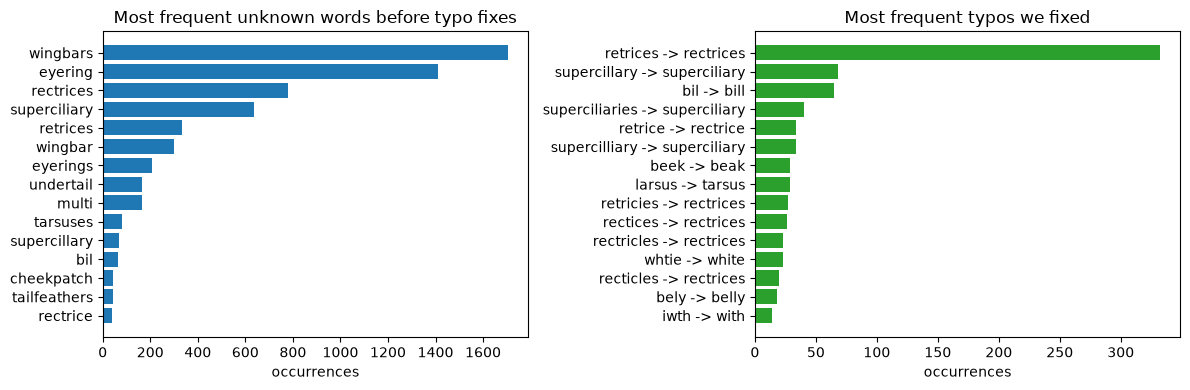

In [43]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
t = typos[:15]
ax[0].barh([w for w, _ in t], [c for _, c in t]); ax[0].invert_yaxis()
ax[0].set_title("Most frequent unknown words before typo fixes")
ax[0].set_xlabel("occurrences")

fixed = sorted(((w, words[w]) for w in TYPO_FIXES if w in words), key=lambda x: -x[1])[:15]
ax[1].barh([f"{w} -> {TYPO_FIXES[w]}" for w, _ in fixed], [c for _, c in fixed], color="tab:green"); ax[1].invert_yaxis()
ax[1].set_title("Most frequent typos we fixed"); ax[1].set_xlabel("occurrences")
save("typos")

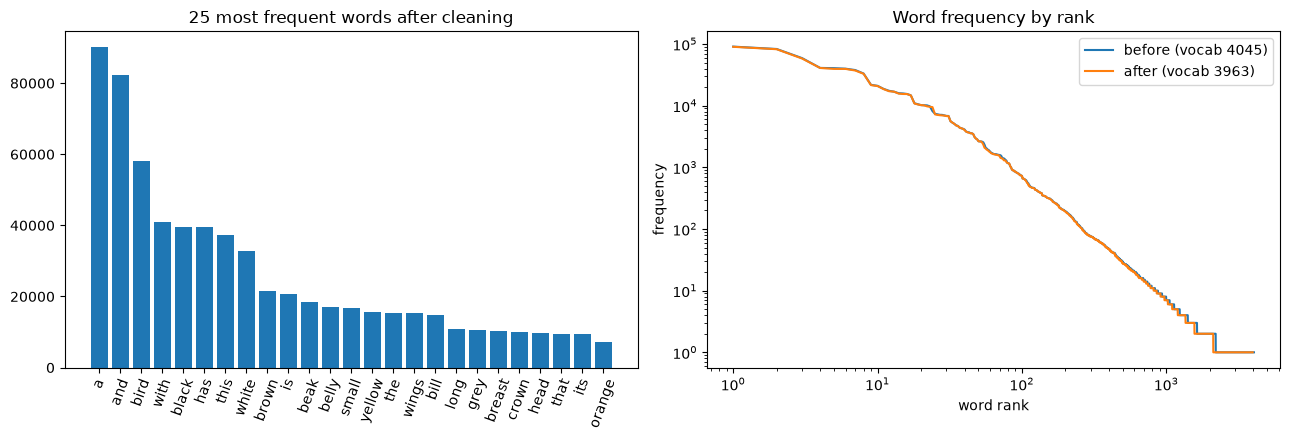

In [44]:
top = words_after.most_common(25)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].bar([w for w, _ in top], [c for _, c in top]); ax[0].tick_params(axis="x", rotation=70)
ax[0].set_title("25 most frequent words after cleaning")

for name, cnt_ in (("before", words), ("after", words_after)):
    freqs = sorted(cnt_.values(), reverse=True)
    ax[1].loglog(range(1, len(freqs) + 1), freqs, label=f"{name} (vocab {len(freqs)})")
ax[1].set_xlabel("word rank"); ax[1].set_ylabel("frequency"); ax[1].legend(); ax[1].set_title("Word frequency by rank")
save("vocabulary")